<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Germany's weather, the next days, at 9 km 🇩🇪
### ECMWF free & open data · IFS 9 km · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/germany/germany_forecast.ipynb)

ECMWF's 9 km forecast (IFS) is **open data**: no login, no fee. This notebook downloads the newest run and
maps how much **rain** falls over Germany in the next three days, or, with one line changed, the **temperature**
tomorrow afternoon, then prints the numbers for the big cities.

**What you need:** a Google account (to use Colab). No other account, no fee, nothing to install. Everything runs on
Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data), IFS 9 km | Total precipitation over the next three days, or 2 m temperature tomorrow at 12 UTC, latest run | CC BY 4.0, © ECMWF |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools, with cartopy.

*Press **Runtime → Run all**. The first run takes a few minutes, mostly installing the tools.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to Germany, 2026.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots ecmwf-opendata

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import numpy as np
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs, cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from ecmwf.opendata import Client

## 1 · Choose what to map

In [3]:
VARIABLE = "rain"      # "rain" (rain over the next DAYS days) or "temp" (2 m temperature tomorrow)
DAYS = 3                # rain map: total from the start of the run, 1 to 6 days
HOUR = 12               # temperature map: tomorrow at this hour, UTC (13:00 in Germany)

AREA = dict(north=55.3, south=47.0, west=5.5, east=15.5)
CAPITAL = ('Berlin', 52.52, 13.405)
CITIES = [("Hamburg", 53.551, 9.994),
          ("Munich", 48.137, 11.576),
          ("Cologne", 50.938, 6.96),
          ("Bonn", 50.737, 7.098),
          ("Frankfurt", 50.11, 8.682),
          ("Stuttgart", 48.776, 9.183),
          ("Leipzig", 51.34, 12.375),
          ("Hanover", 52.375, 9.732)]

SETTINGS = {   # what to ask ECMWF open data for, and how to show it
    "rain": dict(param="tp", unit="mm", label=f"Rain and snow (water) over {DAYS} days (mm)",
                 title=f"Rain over Germany, the next {DAYS} days",
                 convert=lambda f: f * 1000,                                  # metres of water -> mm
                 levels=lambda f: [0.5, 1, 2, 5, 10, 15, 20, 30, 40, 60, 80],
                 ramp=["#e8f5ff", "#a9e3f7", "#79d0ef", "#3f94d0", "#2b5c86", "#4a3fa0", "#6a2d8c"]),
    "temp": dict(param="2t", unit="°C", label="2 m temperature (°C)",
                 title="Temperature over Germany",
                 convert=lambda f: f - 273.15,                                # kelvin -> °C
                 levels=lambda f: list(range(int(np.floor(float(f.min()))) - 1, int(np.ceil(float(f.max()))) + 2)),
                 ramp=["#4a7fc0", "#8ec5e8", "#cfeefc", "#fff3b0", "#ffb562", "#e8623a"]),
}
S = SETTINGS[VARIABLE]

## 2 · Get the latest 9 km forecast (ECMWF open data)

In [4]:
for SOURCE in ("ecmwf", "aws", "google"):      # ECMWF first, then the cloud mirrors if it is busy
    try:
        client = Client(SOURCE)
        run = client.latest(stream="oper", type="fc", param=S["param"], resol="0p1")   # the newest run
        if VARIABLE == "temp":                      # hours from the run to tomorrow at HOUR UTC
            target = dt.datetime.combine(run.date() + dt.timedelta(days=1), dt.time(HOUR))
            STEP = int((target - run).total_seconds() // 3600)
            if STEP < 24: STEP += 24                # an evening run: take the day after
        else:
            STEP = 24 * DAYS                        # accumulated from the start of the run
        client.retrieve(date=run.date(), time=run.hour, step=STEP, stream="oper", type="fc", levtype="sfc",
                        param=S["param"], resol="0p1", target="ifs.grib2")             # resol="0p1" = 9 km
        break
    except Exception as err:
        print(f"{SOURCE} did not answer ({type(err).__name__}), trying the next mirror")
x = ekd.from_source("file", "ifs.grib2").to_xarray()
x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude").sortby("latitude")
dlon, dlat = 1 + 0.5 * (AREA["east"] - AREA["west"]), 1 + 0.25 * (AREA["north"] - AREA["south"])   # a margin: the map is curved
x = x.sel(latitude=slice(AREA["south"] - dlat, AREA["north"] + dlat), longitude=slice(AREA["west"] - dlon, AREA["east"] + dlon))
field = S["convert"](x[list(x.data_vars)[0]].squeeze(drop=True))
valid = run + dt.timedelta(hours=STEP)
print(f"ECMWF IFS 9 km, run {run:%A %d %B %Y, %H} UTC, +{STEP} h")
for n, la, lo in [CAPITAL] + CITIES:
    print(f"  {n:12s} {float(field.sel(latitude=la, longitude=lo, method='nearest')):6.1f} {S['unit']}")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


ECMWF IFS 9 km, run Monday 23 November 2026, 00 UTC, +72 h
  Berlin          0.5 mm
  Hamburg         0.0 mm
  Munich          4.9 mm
  Cologne         0.0 mm
  Bonn            0.0 mm
  Frankfurt       0.0 mm
  Stuttgart       1.0 mm
  Leipzig         0.2 mm
  Hanover         0.0 mm


## 3 · Map it

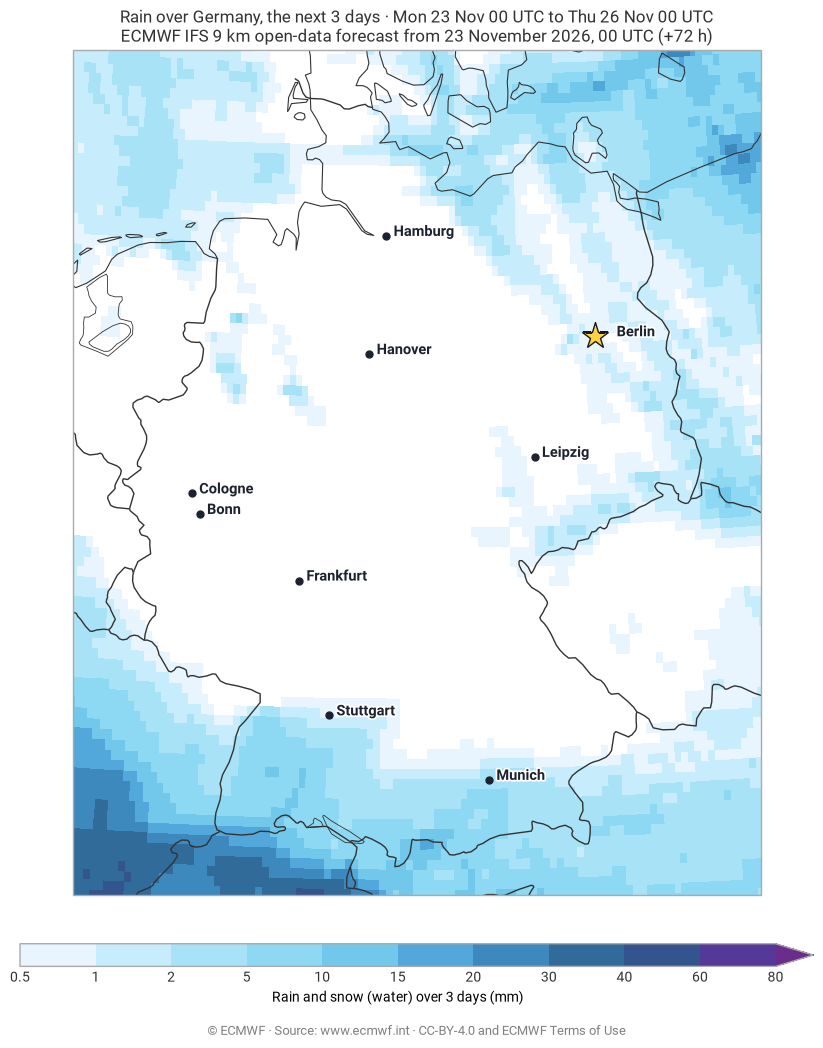

In [5]:
levels = S["levels"](field)
if VARIABLE != "temp":
    field = field.where(field >= levels[0])          # leave the dry areas white
colours = LinearSegmentedColormap.from_list("ramp", S["ramp"])(np.linspace(0, 1, len(levels) - 1))
style = ekp.styles.Style(levels=levels, colors=[tuple(c) for c in colours], extend="both" if VARIABLE == "temp" else "max")
chart = ekp.Map(domain=[AREA["west"], AREA["east"], AREA["south"], AREA["north"]], crs=ccrs.LambertConformal(central_longitude=10.5, central_latitude=51, standard_parallels=(48, 54)), figsize=(10, 10))
chart.pcolormesh(field, style=style)
chart.coastlines(linewidth=0.8, color="#333333"); chart.borders(linewidth=1.0, color="#333333", resolution="medium", transform_first=False)
chart.ax.add_feature(cfeature.LAKES.with_scale("50m"), facecolor="none", edgecolor="#333333", linewidth=0.6)

name, la, lo = CAPITAL
chart.ax.plot(lo, la, "*", ms=20, color="#ffd23f", mec="#1a1a1a", transform=ccrs.PlateCarree(), zorder=12)
for n, la, lo in [CAPITAL] + CITIES:
    if (n, la, lo) != CAPITAL:
        chart.ax.plot(lo, la, "o", ms=5, color="#1d2230", transform=ccrs.PlateCarree(), zorder=10)
    chart.ax.text(lo, la, f"      {n}" if (n, la, lo) == CAPITAL else f"  {n}", transform=ccrs.PlateCarree(), fontsize=10.5, fontweight="bold", zorder=11,
                  color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
chart.legend(label=S["label"])
when = (f"{run:%a %d %b %H} UTC to {valid:%a %d %b %H} UTC" if VARIABLE != "temp" else f"{valid:%A %d %B, %H:%M} UTC")
chart.title(f"{S['title']} · {when}\nECMWF IFS 9 km open-data forecast from {run:%d %B %Y, %H} UTC (+{STEP} h)",
            fontsize=12.5)
chart.attribution("© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use")
chart.save("germany_forecast.png", dpi=130)
chart.show()

## 4 · Your turn 🌍

- **Temperature:** set `VARIABLE = "temp"` in step 1 and run all again; `HOUR = 3` gives the coldest part of the night.
- **A wetter week:** `DAYS = 6` adds up the rain over six days.
- **Snow:** add `"snow": dict(param="sf", ...)` to `SETTINGS`, a copy of `"rain"`: snowfall in mm of water (about 1 cm of fresh snow per mm).
- **Anywhere else:** change `AREA`, `CAPITAL` and `CITIES`, for example `dict(north=49.1, south=46.3, west=9.4, east=17.2)` for Austria.
- **The machine-learning forecast:** add `model="aifs-single"` to both `client` calls and remove `resol="0p1"` (0.25°).

### Data & licence
**ECMWF open data**, CC BY 4.0: `© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.
No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int) ·
[ecmwf-opendata](https://github.com/ecmwf/ecmwf-opendata)